# 01 · Exploratory data analysis

**Question.** What does the data actually cover, how does inflation behave across
countries and time, and what does that imply for modelling?

**Data.** The SQLite warehouse built by `python -m realgrowth.etl` from the
committed API snapshot (`data/raw/api/`, World Bank WDI, IMF WEO, Our World in
Data) plus the legacy ILOSTAT wage extract. Nothing in this notebook re-reads
raw files; it analyses exactly what the API serves.

In [1]:
import sys, json, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in Path.cwd().resolve().parents if (p / "ml" / "src").is_dir())
sys.path.insert(0, str(ROOT / "ml" / "src"))
DB = ROOT / "data" / "realgrowth.db"
MODELS = ROOT / "data" / "models"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

def save(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", dpi=130)
    plt.close(fig)
    display(Image(filename=str(path)))

In [2]:
from realgrowth_ml.data import load_panel
panel = load_panel(DB)
obs = panel.observations
countries = panel.countries
print(f"{len(obs):,} observations · {obs.indicator_id.nunique()} indicators · "
      f"{(~countries.is_aggregate).sum()} countries · built {panel.built_at}")

197,876 observations · 24 indicators · 218 countries · built 2026-10-26T21:56:39+00:00


## 1. Coverage

Density is the share of the 217 countries with a value in each year. Two things
stand out: macro series are dense from the 1990s on, and inequality/poverty
surveys are sparse by nature (they are run every few years). The wage panel is
the thinnest series and stops in 2022.

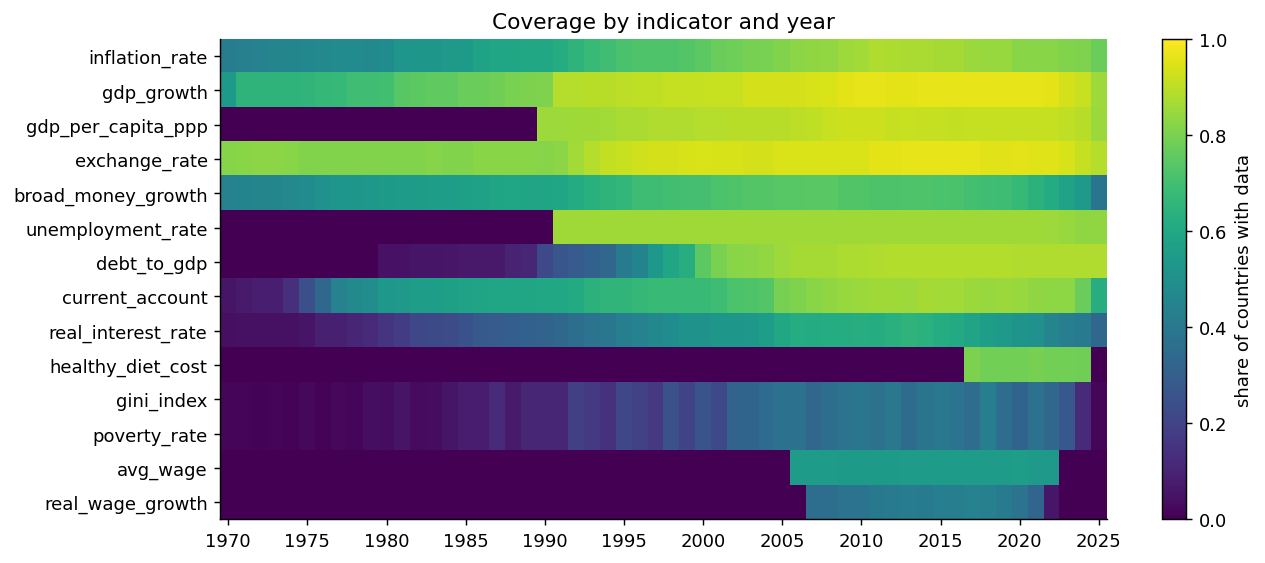

In [3]:
real = obs[obs.iso3.isin(countries.index[~countries.is_aggregate])]
n_countries = (~countries.is_aggregate).sum()
order = ["inflation_rate", "gdp_growth", "gdp_per_capita_ppp", "exchange_rate", "broad_money_growth",
         "unemployment_rate", "debt_to_gdp", "current_account", "real_interest_rate",
         "healthy_diet_cost", "gini_index", "poverty_rate", "avg_wage", "real_wage_growth"]
cov = (real[real.indicator_id.isin(order)].groupby(["indicator_id", "year"]).iso3.nunique()
       .unstack().reindex(order) / n_countries)
cov = cov.loc[:, 1970:]
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(cov.fillna(0).to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(cov)), cov.index)
ticks = list(range(0, cov.shape[1], 5))
ax.set_xticks(ticks, [cov.columns[i] for i in ticks])
ax.grid(False)
fig.colorbar(im, ax=ax, label="share of countries with data")
ax.set_title("Coverage by indicator and year")
save(fig, "eda_coverage")

## 2. The distribution of inflation is extremely heavy-tailed

Annual CPI inflation ranges from deflation to tens of thousands of percent. A
model trained on raw percentages would spend its capacity on a handful of
hyperinflations. The signed-log transform `slog(x) = sign(x)·log(1+|x|)` is
near-linear for ordinary inflation, compresses the tail, and makes errors close
to *relative* errors. All forecasting models are trained and selected on this
scale.

count     9151.00
mean        22.45
std        316.17
min        -17.64
1%          -2.87
5%          -0.25
50%          4.71
95%         35.41
99%        197.97
max      23773.13


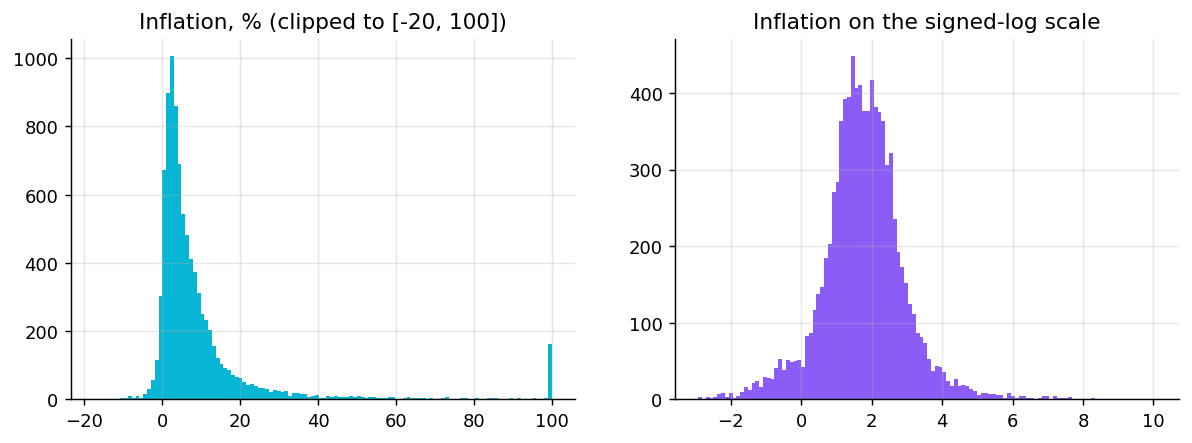

In [4]:
from realgrowth_ml.features import slog
infl = panel.wide("inflation_rate")
values = infl.stack().to_numpy()
print(pd.Series(values).describe(percentiles=[.01, .05, .5, .95, .99]).round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(np.clip(values, -20, 100), bins=120, color="#06b6d4")
axes[0].set_title("Inflation, % (clipped to [-20, 100])")
axes[1].hist(slog(values), bins=120, color="#8b5cf6")
axes[1].set_title("Inflation on the signed-log scale")
save(fig, "eda_inflation_distribution")

## 3. Inflation is persistent, but less than a random walk

The naive forecast "next year equals this year" is a famously hard benchmark.
The scatter of `slog(π_t)` against `slog(π_{t+1})` shows why: points hug the
diagonal. But the slope of a pooled regression is below 1, which says inflation
*mean-reverts*. That is the gap a learned model can exploit.

n=5,995  slope=0.686  intercept=0.484  r=0.709


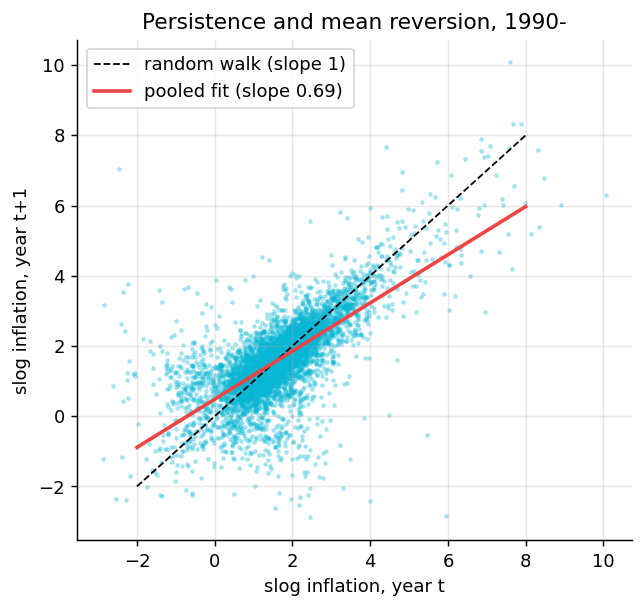

In [5]:
s = slog(infl)
pairs = pd.DataFrame({"now": s.stack(), "next": s.shift(-1, axis=1).stack()}).dropna()
pairs = pairs[pairs.index.get_level_values(1) >= 1990]
slope, intercept = np.polyfit(pairs["now"], pairs["next"], 1)
r = np.corrcoef(pairs["now"], pairs["next"])[0, 1]
print(f"n={len(pairs):,}  slope={slope:.3f}  intercept={intercept:.3f}  r={r:.3f}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(pairs["now"], pairs["next"], s=3, alpha=0.25, color="#06b6d4")
lim = np.array([-2, 8])
ax.plot(lim, lim, "k--", lw=1, label="random walk (slope 1)")
ax.plot(lim, intercept + slope * lim, color="#ef4444", lw=2, label=f"pooled fit (slope {slope:.2f})")
ax.set_xlabel("slog inflation, year t"); ax.set_ylabel("slog inflation, year t+1")
ax.legend(); ax.set_title("Persistence and mean reversion, 1990-")
save(fig, "eda_persistence")

## 4. Inflation has a strong common global component

The cross-country median moves together: the 1970s oil shocks, the long
disinflation, and the 2021-23 surge are visible in almost every country at once.
This motivates the `global_infl_median` features and the *global* (pooled
across countries) model design, and it is also why forecast errors are
correlated within a year, which the significance tests account for.

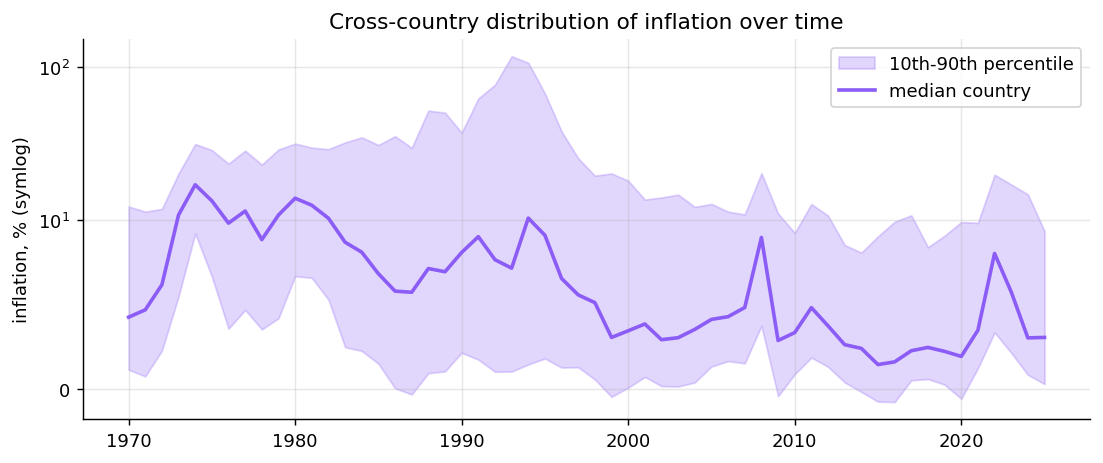

median country inflation by year (last 8):
year
2018    2.45
2019    2.22
2020    1.92
2021    3.47
2022    8.00
2023    5.73
2024    3.01
2025    3.04


In [6]:
q = s.loc[:, 1970:].quantile([0.1, 0.5, 0.9]).T
from realgrowth_ml.features import inv_slog
qp = inv_slog(q)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(qp.index, qp[0.1], qp[0.9], alpha=0.25, color="#8b5cf6", label="10th-90th percentile")
ax.plot(qp.index, qp[0.5], color="#8b5cf6", lw=2, label="median country")
ax.set_yscale("symlog", linthresh=10); ax.set_ylabel("inflation, % (symlog)")
ax.legend(loc="upper right"); ax.set_title("Cross-country distribution of inflation over time")
save(fig, "eda_global_inflation")
print("median country inflation by year (last 8):")
print(qp[0.5].tail(8).round(2).to_string())

## 5. Which macro variables move with next year's inflation?

Spearman rank correlations with *next year's* slog inflation, pooled over
1990 onwards. Money growth, currency depreciation and the GDP deflator carry
signal beyond current inflation, which is what the full LightGBM model uses and
the inflation-only ablation does not.

,spearman_with_next_year,non_missing_share
log_gdp_pc_ppp,-0.371,0.988
log_trade_openness,-0.203,0.865
current_account_lag0,-0.138,0.899
infl_std5,-0.109,0.979
real_interest_lag0,-0.050,0.622
debt_lag0,-0.036,0.862
unemployment_lag0,0.034,0.921
gdp_growth_lag0,0.131,0.992
global_infl_change,0.154,1.000
infl_change,0.162,0.989


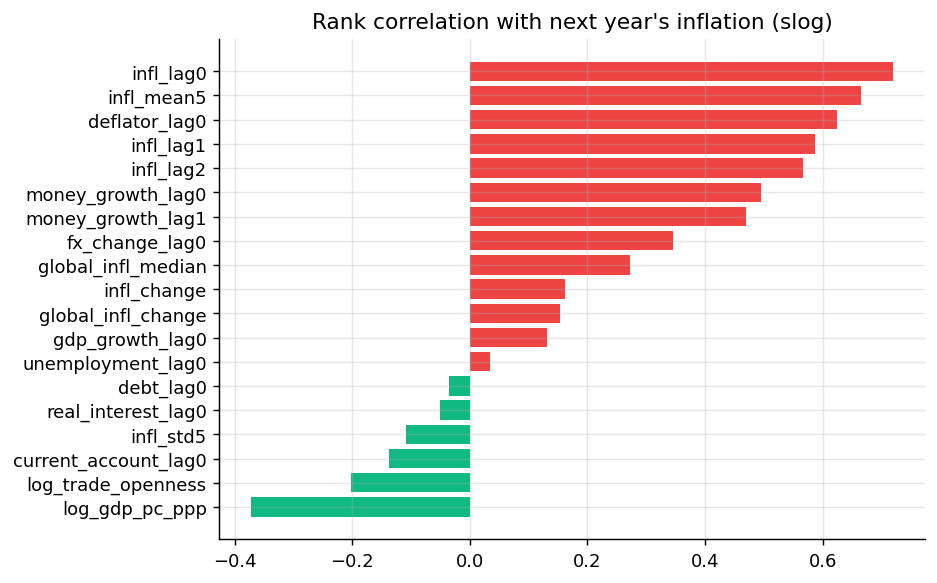

In [7]:
from realgrowth_ml.features import build_feature_frame, FEATURE_NAMES
frame = build_feature_frame(panel, [1])
frame = frame[frame.year >= 1990]
corr = (frame[list(FEATURE_NAMES)].corrwith(frame["target_h1"], method="spearman")
        .drop("region_code").sort_values())
coverage = frame[list(FEATURE_NAMES)].notna().mean().reindex(corr.index)
display(pd.DataFrame({"spearman_with_next_year": corr, "non_missing_share": coverage}).round(3))
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr.index, corr.values, color=["#ef4444" if v > 0 else "#10b981" for v in corr.values])
ax.set_title("Rank correlation with next year's inflation (slog)")
save(fig, "eda_feature_correlations")

## 6. Real wages: why local currency matters

The original project computed real wage growth as **USD** wage growth minus
**domestic** inflation. That conflates a currency move with a pay cut. Below,
the same 2022 numbers computed both ways. In 2022 the dollar strengthened
sharply, so the USD-based method reported European and Japanese real wage
"collapses" that were mostly exchange-rate movements. The ETL now uses the
local-currency definition (the ILO/OECD convention).

,USD-based (old),local currency (new)
iso3,,
USA,-3.2,-3.2
GBR,-14.6,-3.8
DEU,-13.6,-2.2
ITA,-14.5,-3.0
JPN,-17.7,-0.9
CAN,-7.4,-3.6


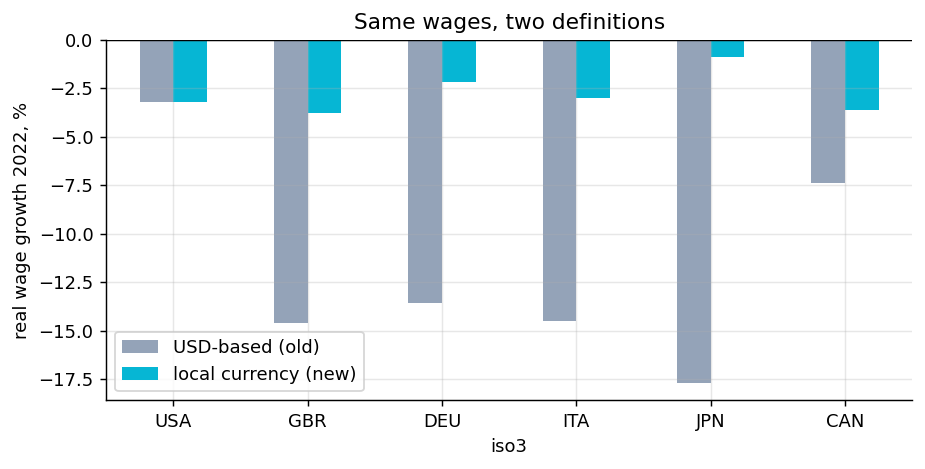

In [8]:
usd = panel.wide("avg_wage"); lcu = panel.wide("avg_wage_lcu")
real_lcu = panel.wide("real_wage_growth")
g_usd = (usd / usd.shift(1, axis=1) - 1) * 100
real_usd = g_usd - infl.reindex(index=g_usd.index, columns=g_usd.columns)
g7 = ["USA", "GBR", "DEU", "ITA", "JPN", "CAN"]
cmp = pd.DataFrame({"USD-based (old)": real_usd.reindex(g7)[2022],
                    "local currency (new)": real_lcu.reindex(g7)[2022]}).round(1)
display(cmp)
fig, ax = plt.subplots(figsize=(8, 3.6))
cmp.plot.bar(ax=ax, color=["#94a3b8", "#06b6d4"]); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("real wage growth 2022, %"); ax.set_title("Same wages, two definitions")
plt.xticks(rotation=0)
save(fig, "eda_real_wage_definitions")

## Takeaways for modelling

1. Model on the signed-log scale; report errors in percentage points *and* on the log scale.
2. The naive forecast is strong; any model must be judged against it out of sample.
3. Inflation mean-reverts and shares a global cycle, so pooled models with global features are justified.
4. Errors will be correlated within years; significance tests must use years, not country-years, as the unit.
5. Macro features add signal but have gaps; tree models handle missing values natively.